### Импорты и данные

In [1]:
import sys
sys.path.append('../src')

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import importlib
import time

from tqdm.auto import tqdm

import rl_train as rl_train_mod
importlib.reload(rl_train_mod)
from rl_train import train_rl

import judge as judge_mod
importlib.reload(judge_mod)
from judge import JudgeModel

import reward_functions as rf_mod
importlib.reload(rf_mod)
from reward_functions import (
    SyntheticReward, RMReward, ItemCenteredReward, build_item_mean_map,
)

from dataset import build_item_vocab
from model import create_model
from reward_model import create_reward_model
from rm_index import RMIndex
from my_evaluate import GPT2Predictor, evaluate_gpt2_fast
from metrics import (
    build_eval_targets, build_context,
    recall_at_k, ndcg_at_k, average_precision_at_k,
)

PROC = Path('../data/processed')
RESULTS = Path('../results')

train_df = pd.read_parquet(PROC / 'train.parquet')
val_df   = pd.read_parquet(PROC / 'val.parquet')
test_df  = pd.read_parquet(PROC / 'test.parquet')

item2idx, idx2item = build_item_vocab(train_df)
vocab_size = len(item2idx) + 2
print(f"Vocab size: {vocab_size}")

Vocab size: 14937


### π_θ и π_ref (два независимых объекта)

In [2]:
def load_gpt2_policy(ckpt):
    m = create_model(vocab_size=vocab_size)
    m.load_state_dict(torch.load(ckpt, map_location='cpu'))
    return m

ref_policy = load_gpt2_policy(RESULTS / 'checkpoints_v2' / 'best_model.pt').cuda().eval()
for p in ref_policy.parameters():
    p.requires_grad = False

policy = load_gpt2_policy(RESULTS / 'checkpoints_v2' / 'best_model.pt').cuda()

assert id(policy) != id(ref_policy)
for (n1, p1), (n2, p2) in zip(policy.named_parameters(), ref_policy.named_parameters()):
    assert n1 == n2 and torch.equal(p1, p2), f"Mismatch in {n1}"
print("π_θ и π_ref — отдельные объекты, веса идентичны, π_ref заморожен")

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 14936), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 14936), got 50256. This may result in unexpected behavior.


π_θ и π_ref — отдельные объекты, веса идентичны, π_ref заморожен


### Reward model v2

In [3]:
rm = create_reward_model(vocab_size=vocab_size,
                         init_from=RESULTS / 'checkpoints_v2' / 'best_model.pt')
rm.load_state_dict(torch.load(RESULTS / 'checkpoints_rm_v2' / 'best_model.pt',
                              map_location='cpu'))
rm = rm.cuda().eval()
for p in rm.parameters():
    p.requires_grad = False
print(f"RM v2: {sum(p.numel() for p in rm.parameters()):,} params, frozen")

[create_reward_model] Backbone: загружено 28 тензоров
[create_reward_model] candidate_emb инициализирован из wte
RM v2: 4,268,289 params, frozen


### RMIndex

In [4]:
all_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
idx = RMIndex(all_df, item2idx, t1='2021-07-24', t2='2021-08-04')

RMIndex: 4,632,197 событий
  train: 2,789,962
  val:   371,021
  test:  474,130


### Helper: measure_target_prob (для синтетического теста)

In [5]:
@torch.no_grad()
def measure_target_prob(model, contexts, target_set, item2idx, max_len=50, device='cuda'):
    was_training = model.training
    model.eval()
    B = len(contexts)
    input_ids = torch.zeros(B, max_len, dtype=torch.long, device=device)
    for i, ctx in enumerate(contexts):
        recent = ctx[-max_len:] if ctx else []
        indexed = [item2idx.get(int(x), 1) for x in recent]
        if indexed:
            input_ids[i, -len(indexed):] = torch.tensor(indexed, device=device)
    probs = torch.softmax(model(input_ids).logits[:, -1, :], dim=-1)
    tgt = torch.tensor([item2idx[int(x)] for x in target_set if int(x) in item2idx],
                       device=device)
    p = float(probs[:, tgt].sum(dim=-1).mean().item())
    if was_training:
        model.train()
    return p

### Helper: score_candidates

In [6]:
@torch.no_grad()
def score_candidates(rm, contexts, cand_idx, item2idx,
                     max_len=50, chunk=2048, batch_b=64, device='cuda'):
    """
    Векторизованная оценка RM для пар (контекст, кандидат).

    contexts  : list[list[item_id]] длины B (история без кандидата)
    cand_idx  : (B, M) LongTensor индексов словаря
    Возвращает: (B, M) float Tensor — sigmoid(RM).
    """
    B = len(contexts)
    L = max_len
    M = cand_idx.shape[1]

    hist = torch.zeros(B, L - 1, dtype=torch.long, device=device)
    for i, ctx in enumerate(contexts):
        recent = ctx[-(L - 1):] if ctx else []
        indexed = [item2idx.get(int(x), 1) for x in recent]
        if indexed:
            hist[i, -len(indexed):] = torch.tensor(indexed, device=device)

    out = []
    for s in range(0, B, batch_b):
        end = min(s + batch_b, B)
        h = hist[s:end].unsqueeze(1).expand(-1, M, -1)   # (b, M, L-1)
        c = cand_idx[s:end].unsqueeze(2)                  # (b, M, 1)
        seq = torch.cat([h, c], dim=2).reshape(-1, L)     # (b*M, L)
        for s2 in range(0, seq.size(0), chunk):
            out.append(torch.sigmoid(rm(seq[s2:s2 + chunk])))
    return torch.cat(out).view(B, M)

### Проверка эквивалентности score_candidates и RMReward

In [7]:
train_rows_all = np.flatnonzero(idx.train_mask)
rng = np.random.default_rng(42)
sample_rows = rng.choice(train_rows_all, size=100, replace=False)

ctxs, acts = [], []
for i in sample_rows:
    hi = idx.day_start[i]
    lo = max(idx.user_start[i], hi - 49)
    ctx = [idx2item[int(idx.items[j])] for j in range(lo, hi)]
    ctxs.append(ctx)
    acts.append(idx2item[int(idx.items[i])])

rm_reward = RMReward(rm=rm, item2idx=item2idx, max_len=50, device='cuda')
ref_scores = rm_reward(ctxs, acts).cuda()   # (100,)

cand_idx = torch.tensor([[item2idx[int(a)]] for a in acts], device='cuda')  # (100, 1)
fast_scores = score_candidates(rm, ctxs, cand_idx, item2idx).squeeze(-1)

diff = (fast_scores - ref_scores).abs().max().item()
print(f"max|diff| = {diff:.2e}")
assert diff < 1e-5, "score_candidates расходится с RMReward"
print("score_candidates эквивалентна RMReward")

max|diff| = 5.96e-08
score_candidates эквивалентна RMReward


### Helper: fixed_eval (единый замер для базы и всех RL-чекпоинтов)

In [8]:
@torch.no_grad()
def _batched_policy_logits(policy, contexts, item2idx, max_len=50, device='cuda',
                            batch_b=512, apply_masking=True, desc=None):
    """
    Батчированный forward политики. Возвращает last-position logits (B, V).
    Если apply_masking=True — маскирует PAD, UNK и seen (по всей истории контекста).
    """
    B = len(contexts)
    out = []
    n_batches = (B + batch_b - 1) // batch_b
    pbar = tqdm(range(0, B, batch_b),
                desc=desc or "policy logits",
                total=n_batches, leave=False)
    for s in pbar:
        end = min(s + batch_b, B)
        inp = torch.zeros(end - s, max_len, dtype=torch.long, device=device)
        for i, ctx in enumerate(contexts[s:end]):
            recent = ctx[-max_len:]
            indexed = [item2idx.get(int(x), 1) for x in recent]
            if indexed:
                inp[i, -len(indexed):] = torch.tensor(indexed, device=device)
        try:
            logits = policy(inp, logits_to_keep=1).logits[:, -1, :].clone()
        except TypeError:
            logits = policy(inp).logits[:, -1, :].clone()
        if apply_masking:
            logits[:, 0] = -1e9
            logits[:, 1] = -1e9
            for i, ctx in enumerate(contexts[s:end]):
                s_items = [item2idx[int(x)] for x in ctx if int(x) in item2idx]
                if s_items:
                    logits[i, torch.tensor(s_items, device=device)] = -1e9
        out.append(logits)
    return torch.cat(out, dim=0)


@torch.no_grad()
def score_candidates(rm, contexts, cand_idx, item2idx,
                     max_len=50, chunk=8192, batch_b=256, device='cuda', desc=None):
    """
    Векторизованная оценка RM для пар (контекст, кандидат).

    contexts  : list[list[item_id]] длины B (история без кандидата)
    cand_idx  : (B, M) LongTensor индексов словаря
    Возвращает: (B, M) float Tensor — sigmoid(RM).

    chunk/batch_b подняты до 8192/256 — на GPU это ×8–10 меньше forward-проходов,
    чем при дефолтных 2048/64.
    """
    B = len(contexts)
    L = max_len
    M = cand_idx.shape[1]

    # hist строим один раз на весь batch
    hist = torch.zeros(B, L - 1, dtype=torch.long, device=device)
    for i, ctx in enumerate(contexts):
        recent = ctx[-(L - 1):] if ctx else []
        indexed = [item2idx.get(int(x), 1) for x in recent]
        if indexed:
            hist[i, -len(indexed):] = torch.tensor(indexed, device=device)

    out = []
    n_batches = (B + batch_b - 1) // batch_b
    pbar = tqdm(range(0, B, batch_b),
                desc=desc or f"RM score {B}x{M}",
                total=n_batches, leave=False)
    for s in pbar:
        end = min(s + batch_b, B)
        h = hist[s:end].unsqueeze(1).expand(-1, M, -1)   # (b, M, L-1)
        c = cand_idx[s:end].unsqueeze(2)                  # (b, M, 1)
        seq = torch.cat([h, c], dim=2).reshape(-1, L)     # (b*M, L)
        for s2 in range(0, seq.size(0), chunk):
            out.append(torch.sigmoid(rm(seq[s2:s2 + chunk])))
    return torch.cat(out).view(B, M)

@torch.no_grad()
def fixed_eval(policy, ref_policy, rm, user_ids, contexts, user_targets,
               item2idx, idx2item, K=10, max_len=50, device='cuda'):
    logits_pi  = _batched_policy_logits(policy,     contexts, item2idx, max_len, device)
    logits_ref = _batched_policy_logits(ref_policy, contexts, item2idx, max_len, device)

    logp_pi  = torch.log_softmax(logits_pi,  dim=-1)
    logp_ref = torch.log_softmax(logits_ref, dim=-1)
    kl = (logp_pi.exp() * (logp_pi - logp_ref)).sum(dim=-1).mean().item()

    topK = torch.topk(logits_pi, K, dim=-1).indices
    rm_scores = score_candidates(rm, contexts, topK, item2idx)
    mean_rm_top10 = rm_scores.mean().item()

    topK_lists = [[idx2item[int(i)] for i in row] for row in topK.cpu()]
    ndcg_v, recall_v, map_v = [], [], []
    for i, uid in enumerate(user_ids):
        targets = user_targets.get(uid, [])
        if not targets:
            continue
        preds = topK_lists[i]
        for t in targets:
            ndcg_v.append(ndcg_at_k(preds, t, K))
            recall_v.append(recall_at_k(preds, t, K))
            map_v.append(average_precision_at_k(preds, t, K))

    return dict(
        kl=kl, mean_rm_top10=mean_rm_top10,
        ndcg10=float(np.mean(ndcg_v)) if ndcg_v else 0.0,
        recall10=float(np.mean(recall_v)) if recall_v else 0.0,
        map10=float(np.mean(map_v)) if map_v else 0.0,
        n_targets=len(ndcg_v),
    )

### Helper: analytic_pareto (аналитический потолок)

In [9]:
@torch.no_grad()
def analytic_pareto(policy, rm, user_ids, contexts, user_targets, item2idx, idx2item,
                    betas, M=200, K=10, max_len=50, device='cuda'):
    B = len(contexts)
    print(f"[pareto] B={B}, M={M}, betas={betas}", flush=True)

    logits = _batched_policy_logits(policy, contexts, item2idx, max_len, device,
                                    desc="pareto: policy logits")
    top = torch.topk(logits, M, dim=-1).indices                        # (B, M)
    logp_ref = torch.log_softmax(logits.gather(1, top), dim=-1)        # (B, M)

    r = score_candidates(rm, contexts, top, item2idx,
                         desc=f"pareto: RM {B}x{M}")                   # (B, M)

    # Таргеты «сплющиваем» один раз — не перебираем 20k пользователей × 6 β
    print("[pareto] flattening targets...", flush=True)
    flat = [(i, t) for i, uid in enumerate(user_ids)
                    for t in user_targets.get(uid, [])]
    print(f"[pareto] {len(flat)} (user, item) пар, {len(betas)} β", flush=True)

    results = {}
    for beta in betas:
        beta_str = "π_ref" if beta is None else f"β={beta}"
        print(f"[pareto] {beta_str} ...", flush=True)

        s = logp_ref if beta is None else logp_ref + r / beta
        pstar = torch.softmax(s, dim=-1)
        kl = (pstar * (torch.log(pstar + 1e-12) - logp_ref)).sum(-1).mean().item()
        Er = (pstar * r).sum(-1).mean().item()

        topK_idx = s.topk(K, dim=-1).indices
        r_top10 = r.gather(1, topK_idx).mean().item()
        topK_lists = [[idx2item[int(i)] for i in row]
                      for row in top.gather(1, topK_idx).cpu()]

        ndcg_v, recall_v = [], []
        for i, t in flat:
            ndcg_v.append(ndcg_at_k(topK_lists[i], t, K))
            recall_v.append(recall_at_k(topK_lists[i], t, K))

        results[beta] = dict(
            Er=Er, kl=kl, r_top10=r_top10,
            ndcg10=float(np.mean(ndcg_v)) if ndcg_v else None,
            recall10=float(np.mean(recall_v)) if recall_v else None,
        )
        m = results[beta]
        print(f"  {beta_str:<10} Er={m['Er']:.4f}  KL={m['kl']:.4f}  "
              f"r_top10={m['r_top10']:.4f}  "
              f"NDCG@10={m['ndcg10']:.4f}  Recall@10={m['recall10']:.4f}",
              flush=True)

    return results

### Сэмплирование контекстов

In [10]:
# 200 train-контекстов для синтетического теста
train_rows_all = np.flatnonzero(idx.train_mask)
np.random.seed(1)
measure_rows = np.random.choice(train_rows_all, size=200, replace=False)
measure_contexts = [
    [idx2item[int(idx.items[j])]
     for j in range(max(idx.user_start[i], idx.day_start[i] - 49), idx.day_start[i])]
    for i in measure_rows
]

# target_set = 20 из топ-200 популярных
popular_top = (train_df.groupby('item_id').size()
               .sort_values(ascending=False).head(200).index.tolist())
np.random.seed(1)
target_set = np.random.choice(popular_top, size=20, replace=False).tolist()
print(f"target_set: {len(target_set)} айтемов из топ-200")

# 20k test-контекстов для fixed_eval и analytic_pareto
test_targets = build_eval_targets(test_df)                # DataFrame [user_id, item_id, last_watch_dt]
test_context = build_context(train_df, val_df)            # {u: {'items': [...], 'last_date': ...}}

test_users = test_targets['user_id'].unique()
np.random.seed(123)
eval_users = np.random.choice(test_users, size=20000, replace=False).tolist()

# Достаём ctx['items'] и обрезаем до 50 (порядок — хронологический, задан build_context)
eval_contexts = []
for u in eval_users:
    ctx = test_context.get(u)
    items = ctx['items'] if ctx else []
    eval_contexts.append(list(items)[-50:])

# Таргеты пользователя — все айтемы в первый активный день test
user_targets = {}
for u in eval_users:
    user_targets[u] = test_targets[test_targets['user_id'] == u]['item_id'].tolist()

n_targets = sum(len(v) for v in user_targets.values())
print(f"Eval: {len(eval_users)} пользователей, {n_targets} таргетов")

_u0 = eval_users[0]
print(f"Пример (user {_u0}): длина контекста = {len(eval_contexts[0])}, "
      f"последние 5 = {eval_contexts[0][-5:]}, "
      f"таргетов = {len(user_targets[_u0])}")
assert all(len(c) > 0 for c in eval_contexts), "Нашли пустой контекст — фильтр холодных должен был исключить"
print("Контексты и таргеты собраны")

target_set: 20 айтемов из топ-200
Eval: 20000 пользователей, 28327 таргетов
Пример (user 453734): длина контекста = 2, последние 5 = [12396, 15297], таргетов = 2
Контексты и таргеты собраны


### Синтетический юнит-тест RL-петли

In [11]:
p_before = measure_target_prob(policy, measure_contexts, target_set, item2idx)
print(f"p_before = {p_before:.4f}")

synthetic_reward = SyntheticReward(target_set=target_set)
policy_ut = load_gpt2_policy(RESULTS / 'checkpoints_v2' / 'best_model.pt').cuda()

history_ut = train_rl(
    policy=policy_ut, ref_policy=ref_policy,
    reward_fn=synthetic_reward, rm_index=idx,
    idx2item=idx2item, item2idx=item2idx,
    n_steps=200, batch_size=32, lr=1e-4, beta_kl=0.0,
    G=16, top_m=None, max_len=50, device='cuda',
    save_dir=str(RESULTS / 'checkpoints_rl_unit_test'),
    seed=1, log_every=20, warmup_steps=20,
)

p_after = measure_target_prob(policy_ut, measure_contexts, target_set, item2idx)
print(f"p_after = {p_after:.4f}  (рост {p_after / p_before:.2f}x)")
assert p_after >= 1.5 * p_before, "Юнит-тест не пройден — стоп!"
print("Петля RL корректна")

del policy_ut
torch.cuda.empty_cache()

p_before = 0.0607
Train contexts available: 2,789,962

Начинаем RL: 200 шагов, batch=32, lr=0.0001, β=0.0, G=16, M=None

Step   20/200 | pg_loss=-0.7569 | kl=0.0926 | mean_r=0.1035 | |A|=0.432 | max π_θ=0.080 | 3s
Step   40/200 | pg_loss=-1.7472 | kl=1.0876 | mean_r=0.4160 | |A|=0.667 | max π_θ=0.358 | 5s
Step   60/200 | pg_loss=-0.9416 | kl=2.9109 | mean_r=0.8086 | |A|=0.327 | max π_θ=0.782 | 8s
Step   80/200 | pg_loss=-0.7315 | kl=3.6768 | mean_r=0.8340 | |A|=0.297 | max π_θ=0.806 | 10s
Step  100/200 | pg_loss=-0.4429 | kl=4.0260 | mean_r=0.9473 | |A|=0.149 | max π_θ=0.927 | 13s
Step  120/200 | pg_loss=-0.4524 | kl=4.2410 | mean_r=0.9492 | |A|=0.148 | max π_θ=0.940 | 15s
Step  140/200 | pg_loss=-0.6434 | kl=3.9323 | mean_r=0.9141 | |A|=0.233 | max π_θ=0.864 | 18s
Step  160/200 | pg_loss=-0.2947 | kl=3.5503 | mean_r=0.9297 | |A|=0.129 | max π_θ=0.900 | 21s
Step  180/200 | pg_loss=-0.5974 | kl=3.9891 | mean_r=0.9219 | |A|=0.215 | max π_θ=0.872 | 23s
Step  200/200 | pg_loss=-0.3030 | kl

### Аналитический потолок (Pareto по β)

In [12]:
FAST = True
if FAST:
    N_EVAL, M_PARETO = 2_000, 50
else:
    N_EVAL, M_PARETO = 20_000, 200

if N_EVAL != len(eval_users):
    np.random.seed(123)
    _users = np.random.choice(test_users, size=N_EVAL, replace=False).tolist()
    _ctxs = []
    for u in _users:
        c = test_context.get(u)
        items = c['items'] if c else []
        _ctxs.append(list(items)[-50:])
    _targets = {u: test_targets[test_targets['user_id'] == u]['item_id'].tolist()
                for u in _users}
else:
    _users, _ctxs, _targets = eval_users, eval_contexts, user_targets

print(f"Pareto: {len(_users)} users, M={M_PARETO}, "
      f"targets={sum(len(v) for v in _targets.values())}")

betas_pareto = [0.03, 0.1, 0.3, 1.0, 3.0, None]
pareto = analytic_pareto(
    policy=ref_policy, rm=rm,
    user_ids=_users, contexts=_ctxs, user_targets=_targets,
    item2idx=item2idx, idx2item=idx2item,
    betas=betas_pareto, M=M_PARETO,
)

print()
print(f"{'β':>8}  {'Er':>7}  {'KL':>7}  {'r_top10':>8}  {'NDCG@10':>8}  {'Recall@10':>10}")
print("-" * 66)
for beta, m in pareto.items():
    b = f"{beta:.3f}" if beta is not None else "  π_ref"
    print(f"{b:>8}  {m['Er']:>7.4f}  {m['kl']:>7.4f}  "
          f"{m['r_top10']:>8.4f}  {m['ndcg10']:>8.4f}  {m['recall10']:>10.4f}")

Pareto: 2000 users, M=50, targets=2767
[pareto] B=2000, M=50, betas=[0.03, 0.1, 0.3, 1.0, 3.0, None]


pareto: policy logits:   0%|          | 0/4 [00:00<?, ?it/s]

pareto: RM 2000x50:   0%|          | 0/8 [00:00<?, ?it/s]

[pareto] flattening targets...
[pareto] 2767 (user, item) пар, 6 β
[pareto] β=0.03 ...
  β=0.03     Er=0.7414  KL=1.6568  r_top10=0.6820  NDCG@10=0.0854  Recall@10=0.1536
[pareto] β=0.1 ...
  β=0.1      Er=0.6815  KL=0.5670  r_top10=0.6659  NDCG@10=0.1069  Recall@10=0.1746
[pareto] β=0.3 ...
  β=0.3      Er=0.6092  KL=0.1277  r_top10=0.6141  NDCG@10=0.1220  Recall@10=0.2013
[pareto] β=1.0 ...
  β=1.0      Er=0.5551  KL=0.0151  r_top10=0.5514  NDCG@10=0.1323  Recall@10=0.2230
[pareto] β=3.0 ...
  β=3.0      Er=0.5350  KL=0.0018  r_top10=0.5232  NDCG@10=0.1349  Recall@10=0.2233
[pareto] π_ref ...
  π_ref      Er=0.5240  KL=0.0000  r_top10=0.5096  NDCG@10=0.1361  Recall@10=0.2255

       β       Er       KL   r_top10   NDCG@10   Recall@10
------------------------------------------------------------------
   0.030   0.7414   1.6568    0.6820    0.0854      0.1536
   0.100   0.6815   0.5670    0.6659    0.1069      0.1746
   0.300   0.6092   0.1277    0.6141    0.1220      0.2013
   1.000  

### Свип по β

In [13]:
# Для каждой — пересоздаём policy из π_ref,
# обучаем 500 шагов, сразу fixed_eval на тех же контекстах, что Pareto.
# Если FAST=True — на 2000 контекстах, иначе на полных 20000.

betas_rl = [0.5, 1.0, 2.0]
n_steps_rl = 500
lr_rl = 1e-5

# Считаем базовую точку (π_ref) ДО свипа — чтобы Δ был честный
print("[base] fixed_eval на π_ref ...")
base_fixed = fixed_eval(
    policy=ref_policy, ref_policy=ref_policy, rm=rm,
    user_ids=_users, contexts=_ctxs, user_targets=_targets,
    item2idx=item2idx, idx2item=idx2item,
)
print(f"[base] Er={base_fixed['mean_rm_top10']:.4f}  "
      f"NDCG@10={base_fixed['ndcg10']:.4f}  Recall@10={base_fixed['recall10']:.4f}\n")

rl_results = {}
histories_by_beta = {}

for beta in betas_rl:
    print(f"\n{'='*70}\nR0 с β={beta}\n{'='*70}")
    policy_b = load_gpt2_policy(RESULTS / 'checkpoints_v2' / 'best_model.pt').cuda()

    t0 = time.time()
    history_b = train_rl(
        policy=policy_b, ref_policy=ref_policy,
        reward_fn=rm_reward, rm_index=idx,
        idx2item=idx2item, item2idx=item2idx,
        n_steps=n_steps_rl, batch_size=64,
        lr=lr_rl, beta_kl=beta, G=8, top_m=200, max_len=50,
        device='cuda',
        save_dir=str(RESULTS / f'checkpoints_rl_r0_beta{beta}'),
        seed=1, log_every=100, warmup_steps=50,
    )
    histories_by_beta[beta] = history_b
    print(f"Обучение: {time.time()-t0:.0f}s")

    metrics = fixed_eval(
        policy=policy_b, ref_policy=ref_policy, rm=rm,
        user_ids=_users, contexts=_ctxs, user_targets=_targets,
        item2idx=item2idx, idx2item=idx2item,
    )
    rl_results[beta] = metrics
    print(f"fixed_eval β={beta}: Er={metrics['mean_rm_top10']:.4f}  "
          f"KL={metrics['kl']:.4f}  NDCG@10={metrics['ndcg10']:.4f}  "
          f"Recall@10={metrics['recall10']:.4f}")

    del policy_b
    torch.cuda.empty_cache()

print("\nСвип завершён")

[base] fixed_eval на π_ref ...


policy logits:   0%|          | 0/4 [00:00<?, ?it/s]

policy logits:   0%|          | 0/4 [00:00<?, ?it/s]

RM score 2000x10:   0%|          | 0/8 [00:00<?, ?it/s]

[base] Er=0.5096  NDCG@10=0.1361  Recall@10=0.2255


R0 с β=0.5
Train contexts available: 2,789,962

Начинаем RL: 500 шагов, batch=64, lr=1e-05, β=0.5, G=8, M=200

Step  100/500 | pg_loss=-0.4481 | kl=0.0707 | mean_r=0.5539 | |A|=0.760 | max π_θ=0.142 | 18s
Step  200/500 | pg_loss=-0.5991 | kl=0.1395 | mean_r=0.6156 | |A|=0.740 | max π_θ=0.185 | 37s
Step  300/500 | pg_loss=-0.5574 | kl=0.1997 | mean_r=0.6004 | |A|=0.740 | max π_θ=0.193 | 54s
Step  400/500 | pg_loss=-0.9148 | kl=0.2781 | mean_r=0.5848 | |A|=0.768 | max π_θ=0.229 | 71s
Step  500/500 | pg_loss=-0.8361 | kl=0.2757 | mean_r=0.6057 | |A|=0.735 | max π_θ=0.208 | 88s

RL завершено: 500 шагов за 88s
Финальные метрики (последние 20 шагов):
  mean_reward = 0.6088
  kl          = 0.2701
Чекпоинты в: ..\results\checkpoints_rl_r0_beta0.5
Обучение: 88s


...

fixed_eval β=1.0: Er=0.5617  KL=0.1626  NDCG@10=0.1286  Recall@10=0.2186

R0 с β=2.0
Train contexts available: 2,789,962

Начинаем RL: 500 шагов, batch=64, lr=1e-05, β=2.0, G=8, M=200

Step  100/500 | pg_loss=-0.4635 | kl=0.0621 | mean_r=0.5491 | |A|=0.763 | max π_θ=0.135 | 17s
Step  200/500 | pg_loss=-0.5400 | kl=0.0791 | mean_r=0.5857 | |A|=0.765 | max π_θ=0.152 | 33s
Step  300/500 | pg_loss=-0.6037 | kl=0.0807 | mean_r=0.5840 | |A|=0.764 | max π_θ=0.157 | 49s
Step  400/500 | pg_loss=-0.5843 | kl=0.0820 | mean_r=0.5586 | |A|=0.764 | max π_θ=0.149 | 66s
Step  500/500 | pg_loss=-0.5230 | kl=0.0864 | mean_r=0.5612 | |A|=0.761 | max π_θ=0.141 | 82s

RL завершено: 500 шагов за 82s
Финальные метрики (последние 20 шагов):
  mean_reward = 0.5727
  kl          = 0.0828
Чекпоинты в: ..\results\checkpoints_rl_r0_beta2.0
Обучение: 82s


policy logits:   0%|          | 0/4 [00:00<?, ?it/s]

policy logits:   0%|          | 0/4 [00:00<?, ?it/s]

RM score 2000x10:   0%|          | 0/8 [00:00<?, ?it/s]

fixed_eval β=2.0: Er=0.5531  KL=0.0976  NDCG@10=0.1324  Recall@10=0.2230

Свип завершён


### Сводная таблица

In [14]:
print(f"{'Модель':>16}  {'KL':>7}  {'Er':>7}  {'Δ Er vs base':>13}  "
      f"{'NDCG@10':>8}  {'Δ NDCG':>8}  {'потолок Er':>11}")
print("-" * 95)

base_Er = base_fixed['mean_rm_top10']
base_NDCG = base_fixed['ndcg10']

print(f"{'base (π_ref)':>16}  {base_fixed['kl']:>7.4f}  {base_Er:>7.4f}  "
      f"{'+0.0%':>13}  {base_NDCG:>8.4f}  {'+0.0%':>8}  {'—':>11}")

for beta, m in rl_results.items():
    dEr = (m['mean_rm_top10'] / base_Er - 1) * 100 if base_Er > 0 else 0
    dND = (m['ndcg10'] / base_NDCG - 1) * 100 if base_NDCG > 0 else 0
    # потолок Er для этой же β из таблицы Pareto
    ceiling = pareto.get(beta, {}).get('Er', None) if isinstance(pareto, dict) else None
    ceil_str = f"{ceiling:.4f}" if ceiling is not None else "—"
    print(f"{f'R0 β={beta}':>16}  {m['kl']:>7.4f}  {m['mean_rm_top10']:>7.4f}  "
          f"{f'{dEr:+.1f}%':>13}  {m['ndcg10']:>8.4f}  {f'{dND:+.1f}%':>8}  {ceil_str:>11}")

          Модель       KL       Er   Δ Er vs base   NDCG@10    Δ NDCG   потолок Er
-----------------------------------------------------------------------------------------------
    base (π_ref)   0.0000   0.5096          +0.0%    0.1361     +0.0%            —
        R0 β=0.5   0.2622   0.5621         +10.3%    0.1240     -8.9%            —
        R0 β=1.0   0.1626   0.5617         +10.2%    0.1286     -5.5%       0.5551
        R0 β=2.0   0.0976   0.5531          +8.5%    0.1324     -2.7%            —


### Выбор победителя

In [15]:
# Критерий: NDCG@10 не ниже base × 0.97 (потеря не более 3%).
# Среди прошедших — максимальный Er.
valid = {b: m for b, m in rl_results.items()
         if m['ndcg10'] >= 0.97 * base_NDCG}

if valid:
    best_beta = max(valid, key=lambda b: valid[b]['mean_rm_top10'])
    print(f"Победитель: β={best_beta}")
    print(f"Er={valid[best_beta]['mean_rm_top10']:.4f}  "
          f"NDCG@10={valid[best_beta]['ndcg10']:.4f}")
else:
    # Ни одна β не проходит порог — берём с минимальной потерей NDCG
    best_beta = min(rl_results, key=lambda b: abs(rl_results[b]['ndcg10'] - 0.97 * base_NDCG))
    print(f" Ни одна β не прошла порог NDCG ≥ 97% base.")
    print(f"  Берём β={best_beta} как минимальную потерю (NDCG={rl_results[best_beta]['ndcg10']:.4f})")

Победитель: β=2.0
Er=0.5531  NDCG@10=0.1324


### Картинки

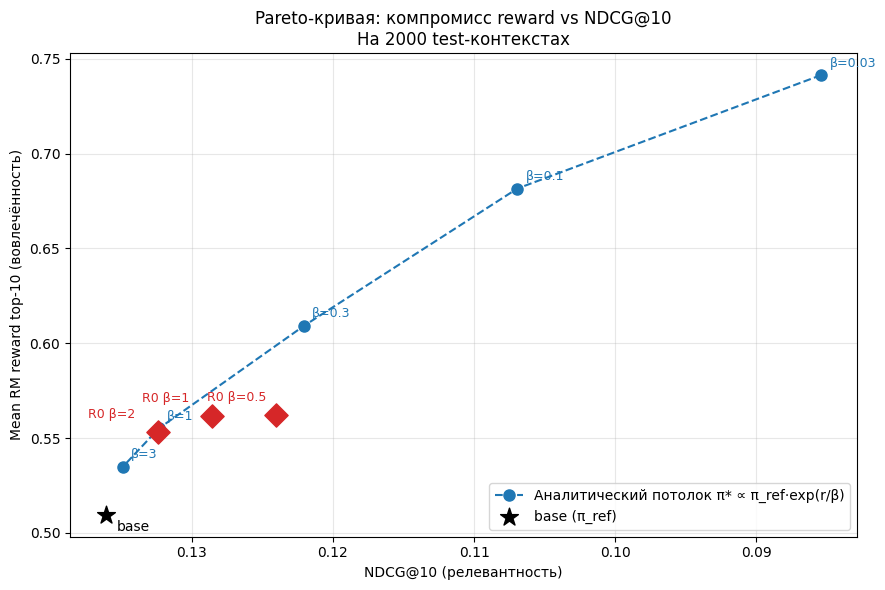

Сохранено: ..\results\rl_pareto_curve.png


In [16]:
fig, ax = plt.subplots(figsize=(9, 6))

# --- Аналитический потолок ---
pareto_pts = [(m['ndcg10'], m['Er'], beta) for beta, m in pareto.items()
              if beta is not None and m['ndcg10'] is not None]
pareto_pts.sort(key=lambda x: x[0])  # по NDCG
xs_p = [p[0] for p in pareto_pts]
ys_p = [p[1] for p in pareto_pts]
ax.plot(xs_p, ys_p, 'o--', color='#1f77b4', linewidth=1.5, markersize=8,
        label='Аналитический потолок π* ∝ π_ref·exp(r/β)')

# Подписи β на аналитических точках
for x, y, beta in pareto_pts:
    ax.annotate(f'β={beta:g}', (x, y), textcoords='offset points',
                xytext=(6, 6), fontsize=9, color='#1f77b4')

# --- Базовая точка ---
ax.scatter([base_fixed['ndcg10']], [base_fixed['mean_rm_top10']],
           s=180, color='black', marker='*', zorder=5, label='base (π_ref)')
ax.annotate('base', (base_fixed['ndcg10'], base_fixed['mean_rm_top10']),
            textcoords='offset points', xytext=(8, -12), fontsize=10)

# --- Реальный RL ---
for beta, m in rl_results.items():
    ax.scatter([m['ndcg10']], [m['mean_rm_top10']],
               s=140, color='#d62728', marker='D', zorder=5)
    ax.annotate(f'R0 β={beta:g}', (m['ndcg10'], m['mean_rm_top10']),
                textcoords='offset points', xytext=(-50, 10), fontsize=9,
                color='#d62728')

ax.set_xlabel('NDCG@10 (релевантность)')
ax.set_ylabel('Mean RM reward top-10 (вовлечённость)')
ax.set_title('Pareto-кривая: компромисс reward vs NDCG@10\n'
             'На 2000 test-контекстах')
ax.grid(alpha=0.3)
ax.legend(loc='lower right')
ax.invert_xaxis()  # NDCG растёт влево, reward — вправо: классическая Pareto-форма

plt.tight_layout()
out_path = RESULTS / 'rl_pareto_curve.png'
plt.savefig(out_path, dpi=130, bbox_inches='tight')
plt.show()
print(f"Сохранено: {out_path}")

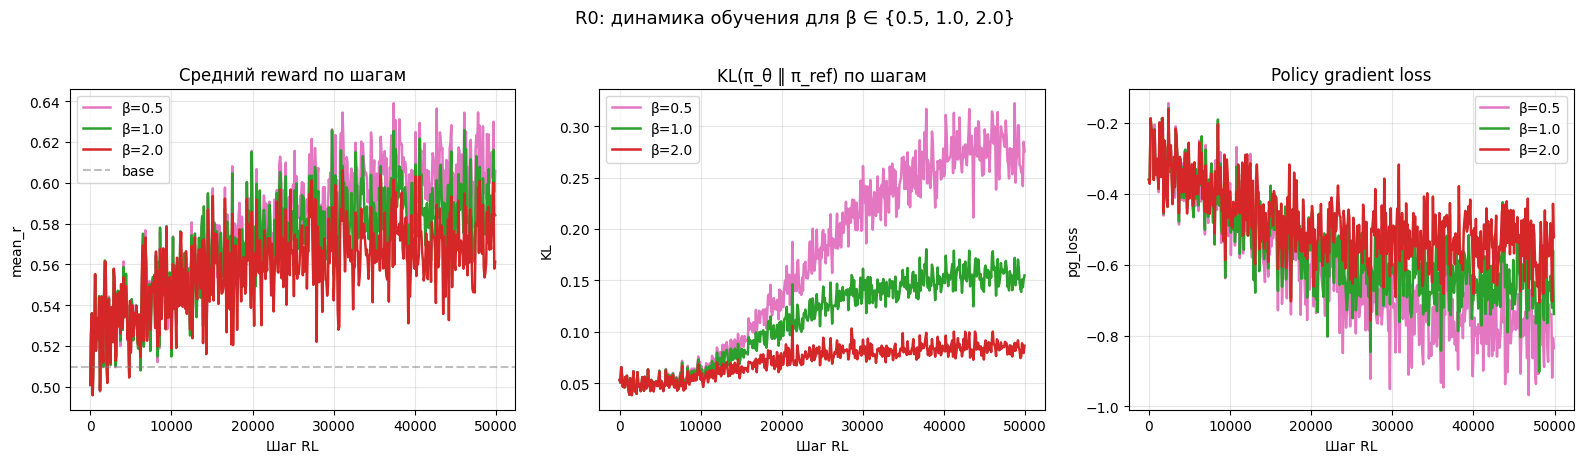

Сохранено: ..\results\rl_r0_training_curves.png


In [17]:
# Проверим, есть ли у нас все три истории
if 'histories_by_beta' not in dir():
    print("histories_by_beta не найден. Пропусти этот график или пересобери:")
    print("histories_by_beta = {} — добавь в свип-ячейку сразу после train_rl:")
    print("histories_by_beta[beta] = history_b")
else:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    colors = {0.5: '#e377c2', 1.0: '#2ca02c', 2.0: '#d62728'}

    for beta, hist in histories_by_beta.items():
        steps = np.arange(len(hist['mean_reward'])) * 100
        c = colors.get(beta, None)
        axes[0].plot(steps, hist['mean_reward'], linewidth=1.8,
                     color=c, label=f'β={beta}')
        axes[1].plot(steps, hist['kl'], linewidth=1.8,
                     color=c, label=f'β={beta}')
        axes[2].plot(steps, hist['pg_loss'], linewidth=1.8,
                     color=c, label=f'β={beta}')

    axes[0].set_title('Средний reward по шагам')
    axes[0].set_xlabel('Шаг RL'); axes[0].set_ylabel('mean_r')
    axes[0].axhline(base_fixed['mean_rm_top10'], color='gray', linestyle='--',
                    alpha=0.5, label='base')
    axes[0].grid(alpha=0.3); axes[0].legend()

    axes[1].set_title('KL(π_θ ‖ π_ref) по шагам')
    axes[1].set_xlabel('Шаг RL'); axes[1].set_ylabel('KL')
    axes[1].grid(alpha=0.3); axes[1].legend()

    axes[2].set_title('Policy gradient loss')
    axes[2].set_xlabel('Шаг RL'); axes[2].set_ylabel('pg_loss')
    axes[2].grid(alpha=0.3); axes[2].legend()

    fig.suptitle('R0: динамика обучения для β ∈ {0.5, 1.0, 2.0}', fontsize=13, y=1.02)
    plt.tight_layout()
    out_path = RESULTS / 'rl_r0_training_curves.png'
    plt.savefig(out_path, dpi=130, bbox_inches='tight')
    plt.show()
    print(f"Сохранено: {out_path}")

### Финальная оценка победителя на полном test

In [18]:
def compute_metrics(preds_dict, targets_df, k_values=(10, 50, 100)):
    max_k = max(k_values)
    accum = {f'{m}@{k}': [] for k in k_values for m in ['Recall', 'NDCG', 'MAP']}
    for _, row in targets_df.iterrows():
        preds = preds_dict.get(row['user_id'], [])[:max_k]
        t = row['item_id']
        for k in k_values:
            accum[f'Recall@{k}'].append(recall_at_k(preds, t, k))
            accum[f'NDCG@{k}'].append(ndcg_at_k(preds, t, k))
            accum[f'MAP@{k}'].append(average_precision_at_k(preds, t, k))
    return {k: float(np.mean(v)) for k, v in accum.items()}

print(f"[test] загружаем чекпоинт β={best_beta}")
policy_best = load_gpt2_policy(
    RESULTS / f'checkpoints_rl_r0_beta{best_beta}' / 'final_model.pt'
).cuda().eval()

print("[test] RL inference на полном test ...")
test_preds_rl = evaluate_gpt2_fast(
    GPT2Predictor(policy_best, item2idx, idx2item, max_len=50),
    test_targets, test_context, k=100, batch_size=512, exclude_seen=True,
)
rl_full = compute_metrics(test_preds_rl, test_targets)

print("[test] base inference на полном test ...")
test_preds_base = evaluate_gpt2_fast(
    GPT2Predictor(ref_policy, item2idx, idx2item, max_len=50),
    test_targets, test_context, k=100, batch_size=512, exclude_seen=True,
)
base_full = compute_metrics(test_preds_base, test_targets)

print(f"\n{'Метрика':<15} {'Base':>10} {'RL (R0)':>10} {'Δ':>10}")
print("=" * 50)
for m in base_full:
    d = (rl_full[m] / base_full[m] - 1) * 100 if base_full[m] > 0 else 0
    print(f"{m:<15} {base_full[m]:>10.4f} {rl_full[m]:>10.4f} {d:>+9.1f}%")

[test] загружаем чекпоинт β=2.0
[test] RL inference на полном test ...
Уникальных юзеров для оценки: 132,323


predict_batch:   0%|          | 0/259 [00:00<?, ?it/s]

[test] base inference на полном test ...
Уникальных юзеров для оценки: 132,323


predict_batch:   0%|          | 0/259 [00:00<?, ?it/s]


Метрика               Base    RL (R0)          Δ
Recall@10           0.2192     0.2179      -0.6%
NDCG@10             0.1304     0.1290      -1.1%
MAP@10              0.1030     0.1016      -1.4%
Recall@50           0.3714     0.3692      -0.6%
NDCG@50             0.1638     0.1621      -1.0%
MAP@50              0.1101     0.1085      -1.4%
Recall@100          0.4592     0.4562      -0.6%
NDCG@100            0.1780     0.1762      -1.0%
MAP@100             0.1113     0.1098      -1.4%


### Замер RM reward на full test

In [19]:
@torch.no_grad()
def mean_rm_reward_on_full_test(preds_dict, context_dict, rm, item2idx,
                                 K=10, batch_size=512, device='cuda'):
    """
    Для каждого пользователя берёт его top-K предсказаний, добавляет к истории,
    прогоняет через RM и усредняет reward. Это и есть «вовлечённость» модели.
    """
    users = list(preds_dict.keys())
    ctxs = [context_dict.get(u, {}).get('items', []) for u in users]

    cand = torch.zeros(len(users), K, dtype=torch.long, device=device)
    for i, u in enumerate(users):
        preds = preds_dict[u][:K]
        for j, item in enumerate(preds):
            cand[i, j] = item2idx.get(int(item), 1)

    rewards = score_candidates(rm, ctxs, cand, item2idx,
                               batch_b=batch_size, device=device)
    return rewards.mean().item()

print("[reward] RM reward топ-10 по базе (π_ref) ...")
reward_base_full = mean_rm_reward_on_full_test(
    test_preds_base, test_context, rm, item2idx, K=10
)

print("[reward] RM reward топ-10 по RL β=2.0 ...")
reward_rl_full = mean_rm_reward_on_full_test(
    test_preds_rl, test_context, rm, item2idx, K=10
)

d_reward = (reward_rl_full / reward_base_full - 1) * 100

print(f"\n{'='*60}")
print(f"RM reward топ-10 (full test, 186 690 таргетов)")
print(f"{'='*60}")
print(f"  Base (π_ref):     {reward_base_full:.4f}")
print(f"  RL R0 β=2.0:      {reward_rl_full:.4f}")
print(f"  Δ reward:         {d_reward:+.1f}%")
print(f"{'='*60}")

# Сводная таблица «reward vs релевантность»
print(f"\n{'Метрика':<20} {'Base':>10} {'RL β=2.0':>12} {'Δ':>10}")
print("-" * 56)
print(f"{'RM reward top-10':<20} {reward_base_full:>10.4f} {reward_rl_full:>12.4f} {d_reward:>+9.1f}%")
for m in ['NDCG@10', 'Recall@10', 'MAP@10']:
    d = (rl_full[m] / base_full[m] - 1) * 100
    print(f"{m:<20} {base_full[m]:>10.4f} {rl_full[m]:>12.4f} {d:>+9.1f}%")

# Сохранить
pd.DataFrame({
    'metric': ['reward_top10', 'NDCG@10', 'Recall@10', 'MAP@10'],
    'base': [reward_base_full, base_full['NDCG@10'], base_full['Recall@10'], base_full['MAP@10']],
    'rl_beta2.0': [reward_rl_full, rl_full['NDCG@10'], rl_full['Recall@10'], rl_full['MAP@10']],
}).to_csv(RESULTS / 'full_test_reward_vs_relevance.csv', index=False)
print(f"\nСохранено: {RESULTS / 'full_test_reward_vs_relevance.csv'}")

[reward] RM reward топ-10 по базе (π_ref) ...


RM score 132323x10:   0%|          | 0/259 [00:00<?, ?it/s]

[reward] RM reward топ-10 по RL β=2.0 ...


RM score 132323x10:   0%|          | 0/259 [00:00<?, ?it/s]


RM reward топ-10 (full test, 186 690 таргетов)
  Base (π_ref):     0.5092
  RL R0 β=2.0:      0.5502
  Δ reward:         +8.0%

Метрика                    Base     RL β=2.0          Δ
--------------------------------------------------------
RM reward top-10         0.5092       0.5502      +8.0%
NDCG@10                  0.1304       0.1290      -1.1%
Recall@10                0.2192       0.2179      -0.6%
MAP@10                   0.1030       0.1016      -1.4%

Сохранено: ..\results\full_test_reward_vs_relevance.csv


### Оценка base vs R0 через судью на полном test

In [20]:
judge = JudgeModel.load(RESULTS / 'checkpoints_judge' / 'judge')

print("[judge] оценка base на полном test ...")
judge_base_full  = judge.score_predictions_topk(test_preds_base, K=10)
mean_item_base   = judge.mean_item_mean_topk(test_preds_base, K=10)

print("[judge] оценка RL β=2.0 на полном test ...")
judge_rl_full    = judge.score_predictions_topk(test_preds_rl, K=10)
mean_item_rl     = judge.mean_item_mean_topk(test_preds_rl, K=10)

d_judge   = (judge_rl_full / judge_base_full - 1) * 100
d_itemmean = (mean_item_rl / mean_item_base - 1) * 100

print(f"\n{'='*72}")
print(f"Сравнение оценок reward (full test, 132 323 пользователя)")
print(f"{'='*72}")
print(f"{'Метрика':<30} {'Base':>10} {'RL β=2.0':>12} {'Δ':>10}")
print("-" * 72)
print(f"{'RM reward top-10':<30} {reward_base_full:>10.4f} {reward_rl_full:>12.4f} "
      f"{(reward_rl_full/reward_base_full-1)*100:>+9.1f}%")
print(f"{'Judge reward top-10':<30} {judge_base_full:>10.4f} {judge_rl_full:>12.4f} "
      f"{d_judge:>+9.1f}%")
print(f"{'Mean item_mean top-10':<30} {mean_item_base:>10.4f} {mean_item_rl:>12.4f} "
      f"{d_itemmean:>+9.1f}%")
print("-" * 72)

# Сохраняем в CSV
pd.DataFrame({
    'metric': ['rm_reward_top10', 'judge_reward_top10', 'mean_item_mean_top10'],
    'base': [reward_base_full, judge_base_full, mean_item_base],
    'rl_beta2.0': [reward_rl_full, judge_rl_full, mean_item_rl],
    'delta_pct': [(reward_rl_full/reward_base_full-1)*100, d_judge, d_itemmean],
}).to_csv(RESULTS / 'judge_eval_full_test.csv', index=False)
print(f"\nСохранено: {RESULTS / 'judge_eval_full_test.csv'}")

[judge] оценка base на полном test ...
[judge] оценка RL β=2.0 на полном test ...

Сравнение оценок reward (full test, 132 323 пользователя)
Метрика                              Base     RL β=2.0          Δ
------------------------------------------------------------------------
RM reward top-10                   0.5092       0.5502      +8.0%
Judge reward top-10                0.4817       0.5069      +5.2%
Mean item_mean top-10              0.4850       0.5245      +8.1%
------------------------------------------------------------------------

Сохранено: ..\results\judge_eval_full_test.csv


*Судья показал, что reward действительно работает. Да, с ним показатели ниже (+5.2% вместо +8.0%), но 5.2% - это всё ещё весомый прирост. Смещение есть (+8.1%), но не критичное (<15%)*

**Тест на взлом reward успешно пройден**